# Segmentasi Semantik Polip pada Citra Kolonoskopi (Kvasir-SEG): U-Net dari Nol vs U-Net dengan Encoder ResNet-34 Pretrained

**Tugas Kelompok – Computer Vision**

Notebook ini berjalan dari awal sampai akhir tanpa intervensi manual (seed acak ditetapkan di sel pertama, dataset diunduh otomatis lewat `kagglehub`).

## Rumusan Masalah

Pada citra kolonoskopi, keputusan klinis sering bergantung pada bentuk dan luas polip, bukan sekadar keberadaannya, sedangkan label citra atau *bounding box* tidak menyimpan informasi tersebut dan anotasi mask jauh lebih mahal. Penelitian ini menggunakan dataset Kvasir-SEG (1.000 citra kolonoskopi beserta mask biner) dengan polip sebagai objek yang disegmentasi, untuk menguji seberapa baik model segmentasi semantik memisahkan polip dari latar, membandingkan U-Net yang dilatih dari nol dengan U-Net berencoder ResNet-34 pretrained ImageNet (diukur dengan Dice dan IoU), serta menelaah informasi apa yang hilang bila masalah yang sama diselesaikan dengan klasifikasi atau deteksi.

**Pertanyaan yang dijawab:**
1. Mana yang lebih akurat pada data uji, U-Net dari nol atau U-Net dengan encoder pretrained ImageNet, diukur dengan Dice dan IoU?
2. Pada citra seperti apa model gagal?
3. Apa yang hilang bila hasil segmentasi hanya disajikan sebagai label citra (klasifikasi) atau *bounding box* (deteksi), dan apakah mask semantik cukup untuk memisahkan objek satu per satu (*instance*)?

## Metode

Kedua model memakai data, augmentasi, loss, dan jadwal pelatihan yang sama, sehingga selisih hasilnya hanya berasal dari encoder (satu-satunya pengecualian yang disengaja adalah *learning rate*, mengikuti praktik umum untuk bobot pretrained).

| Komponen | Model A | Model B |
|---|---|---|
| Arsitektur | U-Net standar, 4 tingkat encoder-decoder | U-Net dengan encoder ResNet-34 |
| Inisialisasi | Acak (dilatih dari nol) | Bobot pretrained ImageNet |
| Pustaka | PyTorch | PyTorch + `segmentation_models_pytorch` |
| Ukuran input | 256 × 256 piksel | 256 × 256 piksel |
| Loss | Dice loss + binary cross-entropy (bobot 1 : 1) | sama |
| Optimizer | Adam, learning rate 1e-3 | Adam, learning rate 1e-4 |
| Augmentasi | Flip horizontal, rotasi ±15°, perubahan kecerahan | sama |
| Penghentian | Early stopping pada Dice validasi, patience 8 epoch | sama |

Dataset Kvasir-SEG bersifat biner (polip vs latar), sehingga digunakan sigmoid dengan Dice + BCE biner; varian multikelas (softmax) tidak diperlukan.

**Metrik** dihitung per citra pada data uji, lalu dirata-rata:

$$\text{Dice} = \frac{2|P \cap G|}{|P| + |G|} \qquad \text{IoU} = \frac{|P \cap G|}{|P \cup G|}$$

*Pixel accuracy* tidak dipakai sebagai dasar kesimpulan karena didominasi piksel latar.

**Catatan pembagian data.** Kvasir-SEG tidak memiliki ID pasien. Sebagai pengganti pembagian "per pasien", citra yang sangat mirip dikelompokkan dengan *difference hash*, lalu pembagian 70/15/15 dilakukan per kelompok (alokasi greedy agar rasio terjaga) sehingga citra mirip tidak tersebar ke subset yang berbeda. Ini merupakan pendekatan pengganti dan bukan jaminan penuh bebas kebocoran antar-pasien.

## Pipeline Eksperimen

Kedua model dilatih pada data yang sama. Hanya keluaran Model B yang diturunkan ke tiga bentuk lain untuk analisis perbandingan.

1. **Eksplorasi data** – hitung jumlah citra, tampilkan 6 contoh citra beserta mask, dan hitung proporsi luas objek.
2. **Pembagian data** – latih 70%, validasi 15%, uji 15% dengan seed tetap (per kelompok citra mirip).
3. **Praproses** – ubah ukuran ke 256 × 256, normalisasi, mask menjadi label 0/1; augmentasi hanya pada data latih.
4. **Pelatihan** – latih Model A dan Model B dengan pengaturan pada bagian Metode; simpan kurva loss dan Dice validasi.
5. **Evaluasi** – hitung Dice dan IoU per citra pada data uji, lalu rata-ratakan.
6. **Perbandingan tugas** – dari prediksi Model B pada satu citra uji, buat label citra, *bounding box*, dan pewarnaan per objek.


### Persiapan: pustaka, seed, dan perangkat
Instalasi pustaka, penetapan seed acak (Python, NumPy, PyTorch, cuDNN deterministik), dan pemilihan perangkat (GPU bila tersedia).

In [ ]:
!pip install -q kagglehub segmentation-models-pytorch albumentations==2.0.8 scikit-image

import os
import random
import glob
import numpy as np
import cv2
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.model_selection import GroupShuffleSplit
from scipy import ndimage as ndi
from skimage.measure import label, regionprops
from skimage.feature import peak_local_max
from skimage.segmentation import watershed
from skimage.color import label2rgb

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
import albumentations as A
from albumentations.pytorch import ToTensorV2
import segmentation_models_pytorch as smp

# Tetapkan Seed Acak
SEED = 42
def seed_everything(seed=SEED):
    random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

seed_everything(SEED)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Menggunakan device: {device}")

Menggunakan device: cuda


### Langkah 1 – Eksplorasi Data
Mengunduh Kvasir-SEG, memvalidasi bahwa setiap citra berpasangan dengan mask bernama sama, menampilkan 6 contoh citra beserta mask, serta menghitung variasi resolusi dan proporsi luas polip terhadap citra.

In [ ]:
import kagglehub
import os
import glob

# Unduh dataset langsung dari Kaggle secara otomatis
dataset_path = kagglehub.dataset_download("debeshjha1/kvasirseg")
print("Lokasi dataset:", dataset_path)

# Cari folder 'images' dan 'masks' secara dinamis di seluruh subdirektori
images_folders = glob.glob(os.path.join(dataset_path, '**', 'images'), recursive=True)
masks_folders = glob.glob(os.path.join(dataset_path, '**', 'masks'), recursive=True)

if len(images_folders) > 0 and len(masks_folders) > 0:
    IMG_DIR = images_folders[0]
    MASK_DIR = masks_folders[0]
else:
    # Fallback default
    IMG_DIR = os.path.join(dataset_path, 'images')
    MASK_DIR = os.path.join(dataset_path, 'masks')

print("Folder images ditemukan di:", IMG_DIR)
print("Folder masks ditemukan di:", MASK_DIR)

image_paths = sorted(glob.glob(os.path.join(IMG_DIR, '*.jpg')) + glob.glob(os.path.join(IMG_DIR, '*.png')))
mask_paths = sorted(glob.glob(os.path.join(MASK_DIR, '*.jpg')) + glob.glob(os.path.join(MASK_DIR, '*.png')))

print(f"Total citra ditemukan : {len(image_paths)}")
print(f"Total mask ditemukan  : {len(mask_paths)}")

# Pastikan setiap citra berpasangan dengan mask bernama sama (urutan sorted tidak cukup sebagai jaminan)
img_stems  = [os.path.splitext(os.path.basename(p))[0] for p in image_paths]
mask_stems = [os.path.splitext(os.path.basename(p))[0] for p in mask_paths]
assert img_stems == mask_stems, "Nama file citra dan mask tidak berpasangan!"
print("Pasangan citra-mask tervalidasi (nama file identik).")

Using Colab cache for faster access to the 'kvasirseg' dataset.
Lokasi dataset: /kaggle/input/kvasirseg
Folder images ditemukan di: /kaggle/input/kvasirseg/Kvasir-SEG/Kvasir-SEG/images
Folder masks ditemukan di: /kaggle/input/kvasirseg/Kvasir-SEG/Kvasir-SEG/masks
Total citra ditemukan : 1000
Total mask ditemukan  : 1000
Pasangan citra-mask tervalidasi (nama file identik).


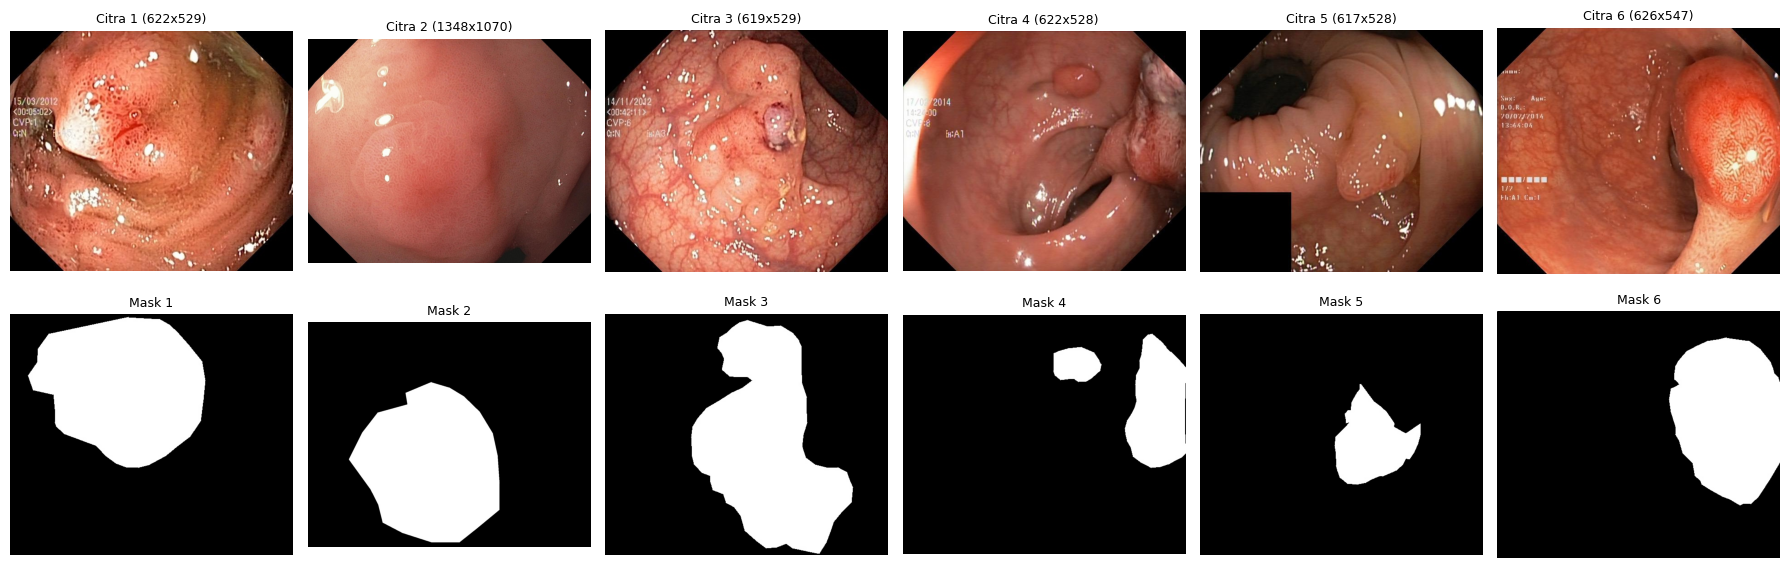

Jumlah variasi resolusi asli citra : 333 ukuran berbeda
Rata-rata proporsi luas objek     : 15.39% dari luas citra
Proporsi objek terkecil - terbesar: 0.47% - 81.18%


In [ ]:
# Tampilkan 6 contoh citra beserta mask-nya (Langkah 1)
fig, axes = plt.subplots(2, 6, figsize=(18, 6))
for i in range(6):
    img = cv2.cvtColor(cv2.imread(image_paths[i]), cv2.COLOR_BGR2RGB)
    mask = cv2.imread(mask_paths[i], cv2.IMREAD_GRAYSCALE)

    axes[0, i].imshow(img)
    axes[0, i].set_title(f"Citra {i+1} ({img.shape[1]}x{img.shape[0]})", fontsize=9)
    axes[0, i].axis('off')

    axes[1, i].imshow(mask, cmap='gray')
    axes[1, i].set_title(f"Mask {i+1}", fontsize=9)
    axes[1, i].axis('off')

plt.tight_layout()
plt.show()

sizes = []
foreground_ratios = []

for img_p, mask_p in zip(image_paths, mask_paths):
    h, w = cv2.imread(img_p).shape[:2]
    sizes.append((w, h))

    m = cv2.imread(mask_p, cv2.IMREAD_GRAYSCALE)
    m_bin = (m > 127).astype(np.float32)
    foreground_ratios.append(m_bin.mean() * 100) # Persentase piksel polip

unique_sizes = set(sizes)
print(f"Jumlah variasi resolusi asli citra : {len(unique_sizes)} ukuran berbeda")
print(f"Rata-rata proporsi luas objek     : {np.mean(foreground_ratios):.2f}% dari luas citra")
print(f"Proporsi objek terkecil - terbesar: {np.min(foreground_ratios):.2f}% - {np.max(foreground_ratios):.2f}%")

### Langkah 2 & 3 – Pembagian Data dan Praproses
- **Langkah 2:** pembagian 70/15/15 dengan seed tetap, dilakukan per kelompok citra mirip (pengganti "per pasien"). Kelompok dialokasikan secara greedy agar rasio mendekati 70/15/15, dan diverifikasi tidak ada kelompok yang muncul di lebih dari satu subset.
- **Langkah 3:** *resize* 256 × 256, normalisasi ImageNet, mask menjadi 0/1. Augmentasi (flip horizontal, rotasi ±15°, kecerahan/kontras) hanya pada data latih.

In [ ]:
# ============ LANGKAH 2: PEMBAGIAN DATA 70 / 15 / 15 (dengan seed tetap) ============
# Kvasir-SEG tidak menyediakan ID pasien. Agar tidak terjadi kebocoran data (frame yang sangat mirip
# dari pasien/video yang sama masuk ke latih DAN uji), citra dikelompokkan lebih dulu berdasarkan
# kemiripan visual (difference hash). Pembagian dilakukan per KELOMPOK sebagai pendekatan pengganti
# "per pasien".
HASH_SIZE = 8
HASH_THRESHOLD = 5     # jarak Hamming maksimum (dari 64 bit) agar dua citra dianggap satu kelompok

def dhash(path, hash_size=HASH_SIZE):
    g = cv2.imread(path, cv2.IMREAD_GRAYSCALE)
    g = cv2.resize(g, (hash_size + 1, hash_size), interpolation=cv2.INTER_AREA)
    return (g[:, 1:] > g[:, :-1]).flatten()

hashes = np.stack([dhash(p) for p in image_paths])
ham = (hashes[:, None, :] != hashes[None, :, :]).sum(-1)   # matriks jarak Hamming (N x N)

# Union-Find untuk menggabungkan citra yang saling mirip
parent = list(range(len(image_paths)))
def find(x):
    while parent[x] != x:
        parent[x] = parent[parent[x]]
        x = parent[x]
    return x
for i, j in zip(*np.where(np.triu(ham <= HASH_THRESHOLD, k=1))):
    ri, rj = find(i), find(j)
    if ri != rj:
        parent[rj] = ri
groups = np.array([find(i) for i in range(len(image_paths))])
sizes_g = np.bincount(np.unique(groups, return_inverse=True)[1])
print(f"Jumlah citra: {len(groups)} | jumlah kelompok mirip: {len(sizes_g)} | "
      f"kelompok terbesar: {sizes_g.max()} citra | kelompok > 1 citra: {(sizes_g > 1).sum()}")

def group_split(groups, ratios=(0.70, 0.15, 0.15), seed=SEED):
    """Alokasi kelompok ke latih/val/uji secara greedy: kelompok terbesar dulu, masuk ke subset yang
    paling kekurangan terhadap targetnya. Hasilnya mendekati rasio target walau ada kelompok besar
    (GroupShuffleSplit biasa bisa sangat miring, mis. 55/12/32), dan deterministik karena seed."""
    rng = np.random.RandomState(seed)
    uniq, inv = np.unique(groups, return_inverse=True)
    members = [np.where(inv == g)[0] for g in range(len(uniq))]
    order = sorted(rng.permutation(len(members)), key=lambda g: -len(members[g]))  # sort stabil
    n = len(groups)
    targets = [r * n for r in ratios]
    subsets = [[], [], []]
    for g in order:
        deficit = [(targets[k] - len(subsets[k])) / targets[k] for k in range(3)]
        subsets[int(np.argmax(deficit))].extend(members[g].tolist())
    return [np.array(sorted(s)) for s in subsets]

idx_all = np.arange(len(image_paths))
train_idx, val_idx, test_idx = group_split(groups)
print("Ukuran 5 kelompok terbesar:", [int(x) for x in sorted(sizes_g, reverse=True)[:5]])

# Verifikasi: tidak ada kelompok yang muncul di dua subset
g_tr, g_va, g_te = set(groups[train_idx]), set(groups[val_idx]), set(groups[test_idx])
assert not (g_tr & g_va) and not (g_tr & g_te) and not (g_va & g_te), "Kebocoran kelompok antar-subset!"

pick = lambda lst, idx: [lst[i] for i in idx]
train_imgs, train_masks = pick(image_paths, train_idx), pick(mask_paths, train_idx)
val_imgs,   val_masks   = pick(image_paths, val_idx),   pick(mask_paths, val_idx)
test_imgs,  test_masks  = pick(image_paths, test_idx),  pick(mask_paths, test_idx)

N = len(image_paths)
print(f"Jumlah Data Latih     : {len(train_imgs)} ({len(train_imgs)/N:.1%})")
print(f"Jumlah Data Validasi  : {len(val_imgs)} ({len(val_imgs)/N:.1%})")
print(f"Jumlah Data Uji       : {len(test_imgs)} ({len(test_imgs)/N:.1%})")
fr = np.array(foreground_ratios)
for name, s, t in (("latih", len(train_imgs), 0.70), ("val", len(val_imgs), 0.15), ("uji", len(test_imgs), 0.15)):
    assert abs(s / N - t) < 0.03, f"Rasio subset {name} menyimpang dari target: {s/N:.1%}"
print(f"Rata-rata luas objek  : latih {fr[train_idx].mean():.2f}% | val {fr[val_idx].mean():.2f}% | uji {fr[test_idx].mean():.2f}%")

# ============ LANGKAH 3: PRAPROSES & AUGMENTASI ============
train_transform = A.Compose([
    A.Resize(256, 256),
    A.HorizontalFlip(p=0.5),
    A.Rotate(limit=15, p=0.5, border_mode=cv2.BORDER_CONSTANT),
    A.RandomBrightnessContrast(brightness_limit=0.2, contrast_limit=0.2, p=0.5),
    A.Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225)),
    ToTensorV2()
], seed=SEED)   # albumentations 2.x memakai generator acak sendiri, bukan seed global

val_test_transform = A.Compose([
    A.Resize(256, 256),
    A.Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225)),
    ToTensorV2()
])

class KvasirDataset(Dataset):
    def __init__(self, img_paths, mask_paths, transform=None):
        self.img_paths = img_paths
        self.mask_paths = mask_paths
        self.transform = transform

    def __len__(self):
        return len(self.img_paths)

    def __getitem__(self, idx):
        img = cv2.cvtColor(cv2.imread(self.img_paths[idx]), cv2.COLOR_BGR2RGB)
        mask = cv2.imread(self.mask_paths[idx], cv2.IMREAD_GRAYSCALE)
        # Ubah mask menjadi label biner 0/1
        mask = (mask > 127).astype(np.float32)

        if self.transform:
            augmented = self.transform(image=img, mask=mask)
            img = augmented['image']
            mask = augmented['mask'].unsqueeze(0) # (1, 256, 256)

        return img, mask

# Generator terpisah agar urutan shuffle data latih reproducible
loader_gen = torch.Generator().manual_seed(SEED)
train_loader = DataLoader(KvasirDataset(train_imgs, train_masks, train_transform), batch_size=16, shuffle=True, generator=loader_gen)
val_loader   = DataLoader(KvasirDataset(val_imgs, val_masks, val_test_transform), batch_size=16, shuffle=False)
test_loader  = DataLoader(KvasirDataset(test_imgs, test_masks, val_test_transform), batch_size=1, shuffle=False)

Jumlah citra: 1000 | jumlah kelompok mirip: 965 | kelompok terbesar: 9 citra | kelompok > 1 citra: 21
Ukuran 5 kelompok terbesar: [9, 5, 4, 3, 3]
Jumlah Data Latih     : 700 (70.0%)
Jumlah Data Validasi  : 150 (15.0%)
Jumlah Data Uji       : 150 (15.0%)
Rata-rata luas objek  : latih 15.28% | val 16.13% | uji 15.18%


### Langkah 4 – Model dan Pelatihan
- **Model A:** U-Net standar 4 tingkat dari nol. **Model B:** U-Net dengan encoder ResNet-34 pretrained ImageNet.
- Loss = Dice + BCE (1 : 1); Adam (A: 1e-3, B: 1e-4); *early stopping* pada Dice validasi dengan patience 8.
- Batas maksimum 40 epoch; penghentian ditentukan oleh *early stopping*, dan sel memberi peringatan bila ada model yang berhenti karena batas epoch.

In [ ]:
# --- MODEL A: U-Net standar 4 tingkat encoder-decoder (dari nol) ---
class DoubleConv(nn.Module):
    def __init__(self, in_c, out_c):
        super().__init__()
        self.conv = nn.Sequential(
            nn.Conv2d(in_c, out_c, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_c),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_c, out_c, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_c),
            nn.ReLU(inplace=True)
        )
    def forward(self, x):
        return self.conv(x)

class UNetScratch(nn.Module):
    def __init__(self, in_channels=3, out_channels=1, features=[64, 128, 256, 512]):
        super().__init__()
        self.downs = nn.ModuleList()
        self.ups = nn.ModuleList()
        self.pool = nn.MaxPool2d(kernel_size=2, stride=2)

        # 4 Tingkat Encoder
        for f in features:
            self.downs.append(DoubleConv(in_channels, f))
            in_channels = f

        # Bottleneck
        self.bottleneck = DoubleConv(features[-1], features[-1]*2)

        # 4 Tingkat Decoder
        for f in reversed(features):
            self.ups.append(nn.ConvTranspose2d(f*2, f, kernel_size=2, stride=2))
            self.ups.append(DoubleConv(f*2, f))

        self.final_conv = nn.Conv2d(features[0], out_channels, kernel_size=1)

    def forward(self, x):
        skip_connections = []
        for down in self.downs:
            x = down(x)
            skip_connections.append(x)
            x = self.pool(x)

        x = self.bottleneck(x)
        skip_connections = skip_connections[::-1]

        for idx in range(0, len(self.ups), 2):
            x = self.ups[idx](x)
            skip = skip_connections[idx//2]
            x = torch.cat((skip, x), dim=1)
            x = self.ups[idx+1](x)

        return self.final_conv(x)

seed_everything(SEED)   # inisialisasi acak yang reproducible
model_A = UNetScratch().to(device)

# --- MODEL B: U-Net dengan encoder ResNet-34 pretrained ImageNet ---
seed_everything(SEED)
model_B = smp.Unet(
    encoder_name="resnet34",
    encoder_weights="imagenet",
    in_channels=3,
    classes=1
).to(device)

config.json:   0%|          | 0.00/156 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 87.3MB            

model.safetensors: downloading bytes:           |  0.00B            

In [ ]:
dice_loss_fn = smp.losses.DiceLoss(mode='binary', from_logits=True)
bce_loss_fn  = nn.BCEWithLogitsLoss()

def combined_loss(pred, target):
    return dice_loss_fn(pred, target) + bce_loss_fn(pred, target)

def compute_metrics_per_image(preds_logits, targets, threshold=0.5):
    probs = torch.sigmoid(preds_logits)
    preds = (probs > threshold).float()

    dices, ious = [], []
    for p, g in zip(preds, targets):
        p_flat = p.view(-1)
        g_flat = g.view(-1)

        intersection = (p_flat * g_flat).sum().item()
        sum_pg = p_flat.sum().item() + g_flat.sum().item()
        union = sum_pg - intersection

        dice = (2.0 * intersection + 1e-7) / (sum_pg + 1e-7)
        iou  = (intersection + 1e-7) / (union + 1e-7)
        dices.append(dice)
        ious.append(iou)
    return dices, ious

# ============ LANGKAH 4: PELATIHAN ============
# Batas maksimum 40 epoch (sesuai laporan). Penghentian ditentukan oleh early stopping
# (Dice validasi, patience 8) sesuai tabel Metode; sel memberi peringatan bila ada model yang
# berhenti karena batas epoch.
MAX_EPOCHS = 40
PATIENCE = 8

def train_model(model, model_name, lr, max_epochs=MAX_EPOCHS, patience=PATIENCE):
    seed_everything(SEED)                      # urutan batch sama untuk kedua model
    loader_gen.manual_seed(SEED)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    history = {'train_loss': [], 'val_loss': [], 'val_dice': []}

    best_val_dice = 0.0
    best_epoch = 0
    patience_counter = 0
    stopped_early = False
    save_path = f"{model_name}_best.pth"

    for epoch in range(1, max_epochs + 1):
        model.train()
        train_loss = 0.0
        for imgs, masks in train_loader:
            imgs, masks = imgs.to(device), masks.to(device)
            optimizer.zero_grad()
            outputs = model(imgs)
            loss = combined_loss(outputs, masks)
            loss.backward()
            optimizer.step()
            train_loss += loss.item() * imgs.size(0)
        train_loss /= len(train_loader.dataset)

        # Validasi
        model.eval()
        val_loss = 0.0
        val_dices = []
        with torch.no_grad():
            for imgs, masks in val_loader:
                imgs, masks = imgs.to(device), masks.to(device)
                outputs = model(imgs)
                loss = combined_loss(outputs, masks)
                val_loss += loss.item() * imgs.size(0)
                d, _ = compute_metrics_per_image(outputs, masks)
                val_dices.extend(d)

        val_loss /= len(val_loader.dataset)
        mean_val_dice = float(np.mean(val_dices))

        history['train_loss'].append(train_loss)
        history['val_loss'].append(val_loss)
        history['val_dice'].append(mean_val_dice)

        print(f"[{model_name}] Epoch {epoch:03d}/{max_epochs} | Train Loss: {train_loss:.4f} | Val Loss: {val_loss:.4f} | Val Dice: {mean_val_dice:.4f}")

        # Early Stopping berdasarkan Dice validasi
        if mean_val_dice > best_val_dice:
            best_val_dice = mean_val_dice
            best_epoch = epoch
            patience_counter = 0
            torch.save(model.state_dict(), save_path)
        else:
            patience_counter += 1
            if patience_counter >= patience:
                stopped_early = True
                print(f"Early stopping {model_name} pada epoch {epoch}. Epoch terbaik: {best_epoch} (Val Dice: {best_val_dice:.4f})")
                break

    if not stopped_early:
        print(f"PERINGATAN: {model_name} mencapai batas {max_epochs} epoch tanpa early stopping "
              f"(epoch terbaik {best_epoch}). Naikkan MAX_EPOCHS agar perbandingan adil.")
    history['epochs_run'] = epoch
    history['stopped_early'] = stopped_early
    pd.DataFrame({k: history[k] for k in ('train_loss', 'val_loss', 'val_dice')}).rename_axis('epoch').to_csv(f"{model_name}_history.csv")
    return history, best_epoch, save_path

print("=== Melatih Model A (U-Net dari nol) ===")
hist_A, best_ep_A, path_A = train_model(model_A, "Model_A", lr=1e-3)

print("\n=== Melatih Model B (U-Net + ResNet-34 Pretrained) ===")
hist_B, best_ep_B, path_B = train_model(model_B, "Model_B", lr=1e-4)

=== Melatih Model A (U-Net dari nol) ===
[Model_A] Epoch 001/40 | Train Loss: 1.1782 | Val Loss: 1.1169 | Val Dice: 0.3784
[Model_A] Epoch 002/40 | Train Loss: 1.0782 | Val Loss: 1.0751 | Val Dice: 0.3860
[Model_A] Epoch 003/40 | Train Loss: 1.0511 | Val Loss: 1.1967 | Val Dice: 0.2730
[Model_A] Epoch 004/40 | Train Loss: 1.0104 | Val Loss: 1.2643 | Val Dice: 0.4027
[Model_A] Epoch 005/40 | Train Loss: 0.9606 | Val Loss: 0.9446 | Val Dice: 0.4746
[Model_A] Epoch 006/40 | Train Loss: 0.9129 | Val Loss: 0.8639 | Val Dice: 0.4816
[Model_A] Epoch 007/40 | Train Loss: 0.9076 | Val Loss: 1.0757 | Val Dice: 0.2712
[Model_A] Epoch 008/40 | Train Loss: 0.9014 | Val Loss: 0.9240 | Val Dice: 0.3509
[Model_A] Epoch 009/40 | Train Loss: 0.8684 | Val Loss: 1.0858 | Val Dice: 0.3015
[Model_A] Epoch 010/40 | Train Loss: 0.8740 | Val Loss: 0.8703 | Val Dice: 0.4256
[Model_A] Epoch 011/40 | Train Loss: 0.8464 | Val Loss: 0.8526 | Val Dice: 0.4349
[Model_A] Epoch 012/40 | Train Loss: 0.8402 | Val Loss: 0

### Langkah 5 – Evaluasi pada Data Uji
Bobot terbaik (Dice validasi tertinggi) dimuat, lalu Dice dan IoU dihitung per citra uji dan dirata-rata. Sel ini juga menghasilkan Tabel 1, kurva pelatihan (Gambar 1), dan tiga prediksi terbaik/terburuk Model B (Gambar 2).


=== TABEL 1. Kinerja Segmentasi pada Data Uji ===
                          Model   Dice    IoU  Epoch terbaik  Epoch dijalankan Berhenti karena
              A. U-Net dari nol 0.5216 0.3858             12                20  early stopping
B. U-Net + ResNet-34 pretrained 0.8506 0.7773             12                20  early stopping


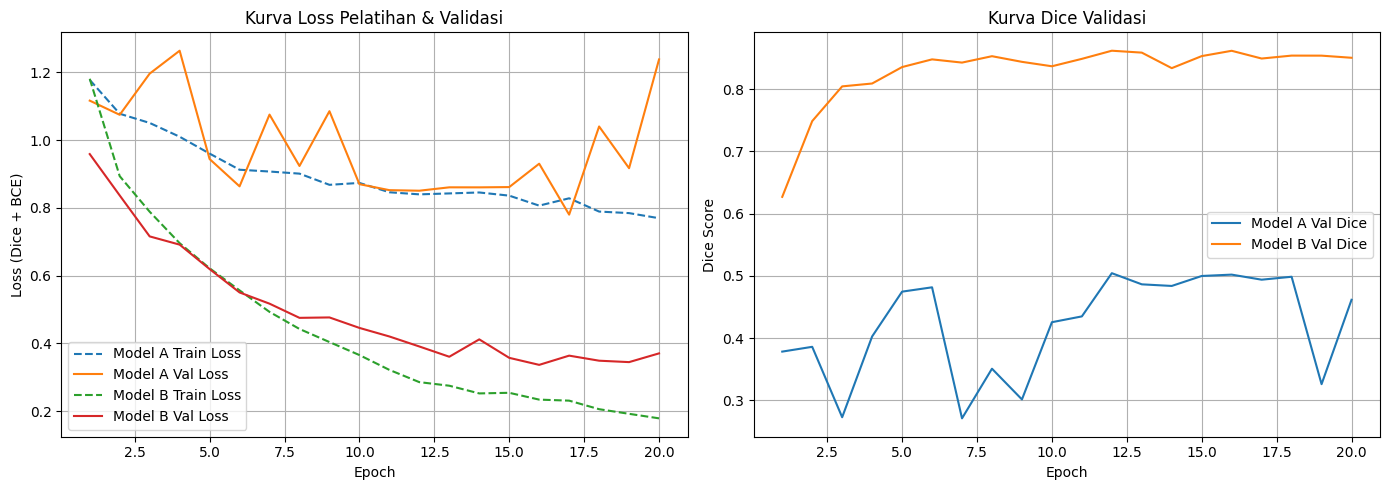

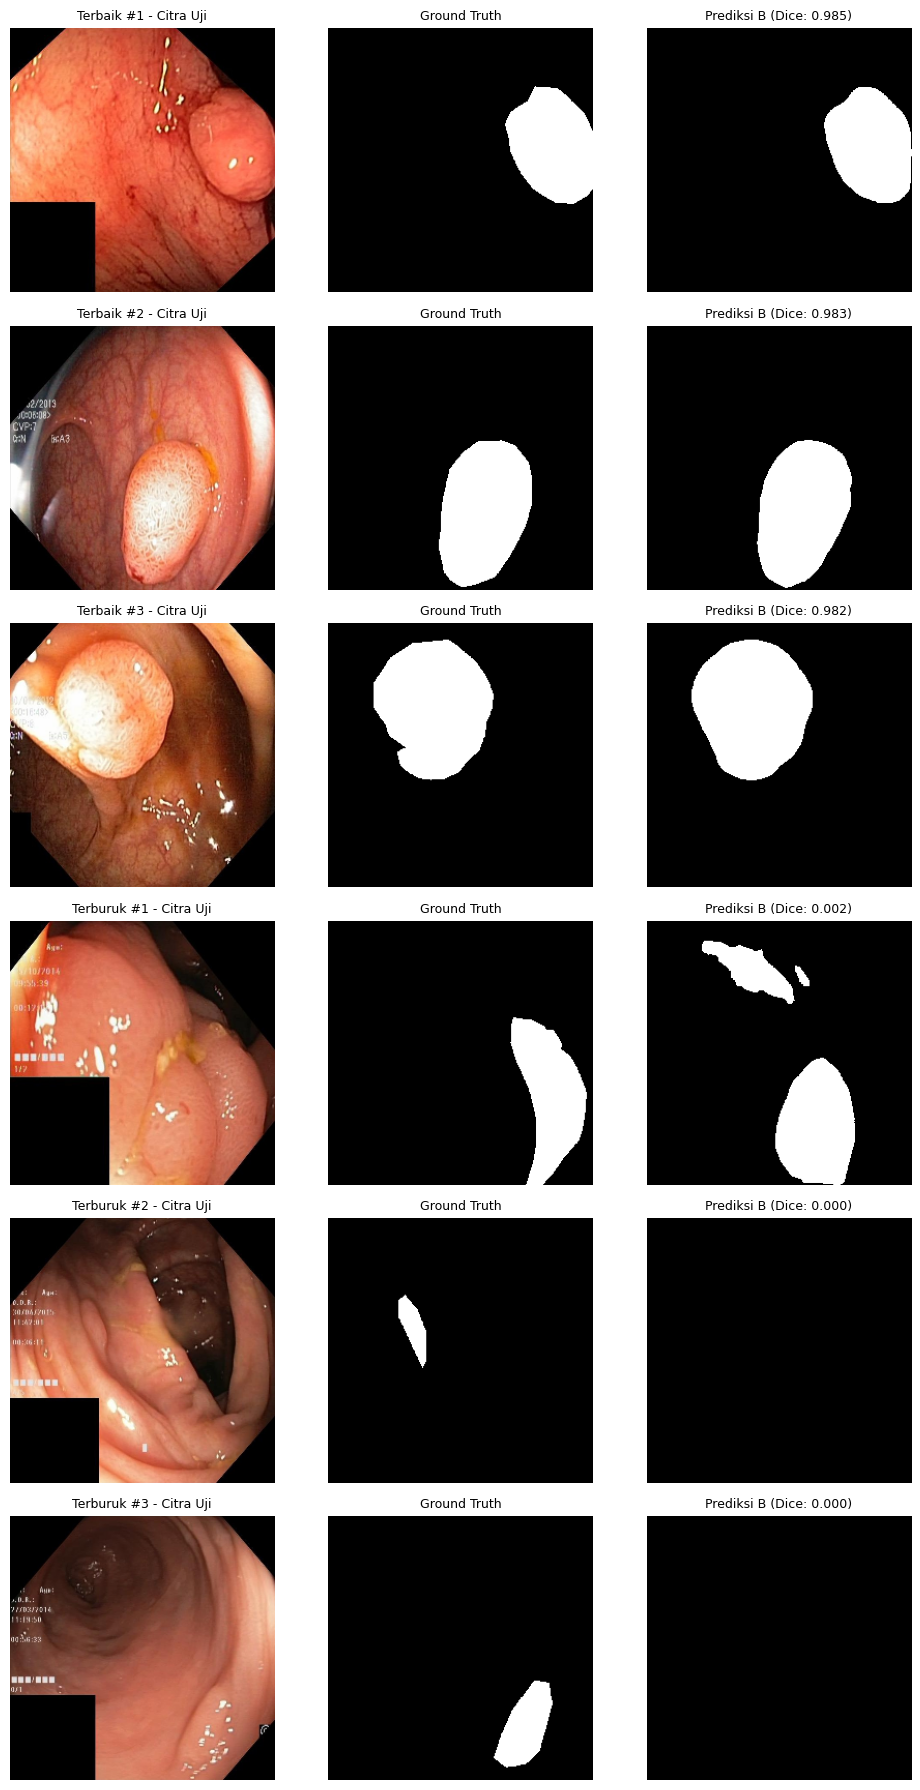

In [ ]:
def evaluate_test(model, weight_path):
    model.load_state_dict(torch.load(weight_path, map_location=device))
    model.eval()
    results = []
    with torch.no_grad():
        for idx, (img, mask) in enumerate(test_loader):
            img_dev, mask_dev = img.to(device), mask.to(device)
            out = model(img_dev)
            d, iou = compute_metrics_per_image(out, mask_dev)
            pred_bin = (torch.sigmoid(out) > 0.5).cpu().numpy()[0, 0]
            results.append({
                'idx': idx,
                'dice': d[0],
                'iou': iou[0],
                'pred': pred_bin,
                'gt': mask.numpy()[0, 0]
            })
    return results

res_A = evaluate_test(model_A, path_A)
res_B = evaluate_test(model_B, path_B)

# --- TABEL 1 ---
df_tabel1 = pd.DataFrame({
    'Model': ['A. U-Net dari nol', 'B. U-Net + ResNet-34 pretrained'],
    'Dice': [f"{np.mean([r['dice'] for r in res_A]):.4f}", f"{np.mean([r['dice'] for r in res_B]):.4f}"],
    'IoU':  [f"{np.mean([r['iou'] for r in res_A]):.4f}",  f"{np.mean([r['iou'] for r in res_B]):.4f}"],
    'Epoch terbaik': [best_ep_A, best_ep_B],
    'Epoch dijalankan': [hist_A['epochs_run'], hist_B['epochs_run']],
    'Berhenti karena': ['early stopping' if hist_A['stopped_early'] else 'batas epoch',
                        'early stopping' if hist_B['stopped_early'] else 'batas epoch']
})
print("\n=== TABEL 1. Kinerja Segmentasi pada Data Uji ===")
print(df_tabel1.to_string(index=False))

# --- GAMBAR 1: Kurva Loss dan Dice Validasi ---
ep_A = range(1, len(hist_A['val_dice']) + 1)   # sumbu-x mulai dari epoch 1
ep_B = range(1, len(hist_B['val_dice']) + 1)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(ep_A, hist_A['train_loss'], label='Model A Train Loss', linestyle='--')
axes[0].plot(ep_A, hist_A['val_loss'], label='Model A Val Loss')
axes[0].plot(ep_B, hist_B['train_loss'], label='Model B Train Loss', linestyle='--')
axes[0].plot(ep_B, hist_B['val_loss'], label='Model B Val Loss')
axes[0].set_title('Kurva Loss Pelatihan & Validasi')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss (Dice + BCE)')
axes[0].legend()
axes[0].grid(True)

axes[1].plot(ep_A, hist_A['val_dice'], label='Model A Val Dice')
axes[1].plot(ep_B, hist_B['val_dice'], label='Model B Val Dice')
axes[1].set_title('Kurva Dice Validasi')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Dice Score')
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.savefig('Gambar_1_Kurva_Training.png', dpi=300)
plt.show()

# --- GAMBAR 2: 3 Prediksi Terbaik dan 3 Terburuk Model B ---
sorted_B = sorted(res_B, key=lambda x: x['dice'], reverse=True)
top3 = sorted_B[:3]
bot3 = sorted_B[-3:]

def get_raw_resized_img(idx):
    img = cv2.cvtColor(cv2.imread(test_imgs[idx]), cv2.COLOR_BGR2RGB)
    return cv2.resize(img, (256, 256))

fig, axes = plt.subplots(6, 3, figsize=(10, 18))
samples = top3 + bot3
labels_row = ['Terbaik #1', 'Terbaik #2', 'Terbaik #3', 'Terburuk #1', 'Terburuk #2', 'Terburuk #3']

for row, (item, tag) in enumerate(zip(samples, labels_row)):
    raw_img = get_raw_resized_img(item['idx'])
    axes[row, 0].imshow(raw_img)
    axes[row, 0].set_title(f"{tag} - Citra Uji", fontsize=9)
    axes[row, 0].axis('off')

    axes[row, 1].imshow(item['gt'], cmap='gray')
    axes[row, 1].set_title("Ground Truth", fontsize=9)
    axes[row, 1].axis('off')

    axes[row, 2].imshow(item['pred'], cmap='gray')
    axes[row, 2].set_title(f"Prediksi B (Dice: {item['dice']:.3f})", fontsize=9)
    axes[row, 2].axis('off')

plt.tight_layout()
plt.savefig('Gambar_2_Terbaik_Terburuk.png', dpi=300)
plt.show()

### Langkah 6 – Perbandingan Tugas dari Prediksi Model B
Prediksi mask Model B diturunkan menjadi (1) label citra, (2) *bounding box* per komponen, (3) mask semantik, dan (4) pewarnaan instance dengan `skimage.measure.label`. Komponen < 20 piksel dibuang secara konsisten. Sebagai pembanding terhadap pertanyaan 3 ditambahkan ground truth, kontur tumpang-tindih, dan *watershed*; sel juga merangkum berapa banyak citra uji yang memiliki lebih dari satu objek.

Jumlah objek terpisah per citra uji (baris = ground truth, kolom = prediksi Model B):
n_pred  0    1   2  3
n_gt                 
1       2  121  18  3
2       0    3   2  1

Citra uji dengan prediksi tanpa objek (klasifikasi 'normal'): 2 dari 150

Citra terpilih: indeks uji 111 | alasan: ground truth dan prediksi sama-sama >= 2 objek | Dice=0.896


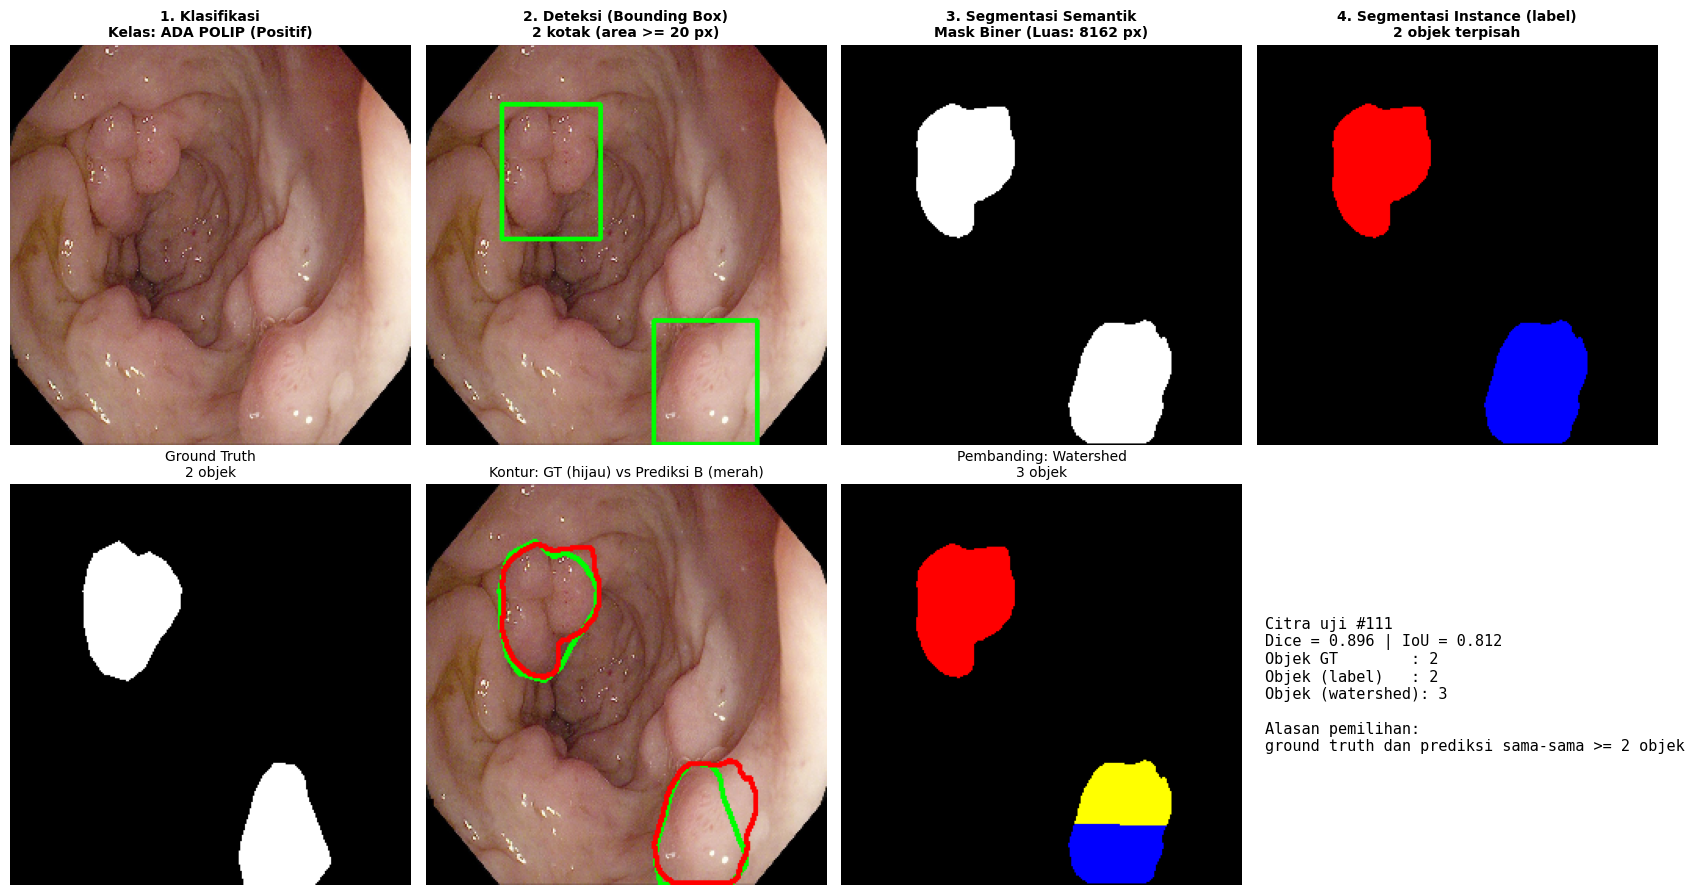

In [ ]:
# ============ LANGKAH 6: PERBANDINGAN TUGAS (dari prediksi Model B) ============
MIN_AREA = 20   # komponen < 20 piksel dianggap noise; dipakai KONSISTEN untuk hitungan, kotak, dan warna

def clean_mask(m, min_area=MIN_AREA):
    """Hapus komponen terhubung kecil agar jumlah objek, kotak, dan label instance selalu sama."""
    m = m.astype(np.uint8)
    lab = label(m)
    out = np.zeros_like(m)
    for p in regionprops(lab):
        if p.area >= min_area:
            out[lab == p.label] = 1
    return out

def watershed_instances(mask, min_distance=15):
    """Pemisah objek yang menempel: watershed pada peta jarak (distance transform)."""
    mask = mask.astype(bool)
    dist = ndi.distance_transform_edt(mask)
    coords = peak_local_max(dist, min_distance=min_distance, labels=label(mask))
    markers = np.zeros(mask.shape, dtype=np.int32)
    for i, (r, c) in enumerate(coords, 1):
        markers[r, c] = i
    return watershed(-dist, markers, mask=mask)

# --- Ringkasan seluruh data uji: seberapa sering mask menghasilkan >1 objek? (bahan untuk pertanyaan 3) ---
rows = []
for r in res_B:
    rows.append({'idx': r['idx'], 'dice': r['dice'],
                 'n_gt':   label(clean_mask(r['gt'])).max(),
                 'n_pred': label(clean_mask(r['pred'])).max()})
df_inst = pd.DataFrame(rows)
print("Jumlah objek terpisah per citra uji (baris = ground truth, kolom = prediksi Model B):")
print(pd.crosstab(df_inst['n_gt'], df_inst['n_pred'], rownames=['n_gt'], colnames=['n_pred']))
print(f"\nCitra uji dengan prediksi tanpa objek (klasifikasi 'normal'): {(df_inst['n_pred'] == 0).sum()} dari {len(df_inst)}")

# --- Pilih SATU citra uji secara deterministik ---
#   prioritas 1: ground truth DAN prediksi sama-sama >= 2 objek (contoh multi-objek yang valid)
#   prioritas 2: hanya prediksi >= 2 objek (kemungkinan fragmen/false positive)
#   prioritas 3: citra dengan Dice tertinggi
df_sorted = df_inst.sort_values('dice', ascending=False)
cand = df_sorted[(df_sorted.n_gt >= 2) & (df_sorted.n_pred >= 2)]
if len(cand):
    reason = "ground truth dan prediksi sama-sama >= 2 objek"
else:
    cand = df_sorted[df_sorted.n_pred >= 2]
    reason = "hanya prediksi yang >= 2 objek (kemungkinan fragmen)"
if not len(cand):
    cand = df_sorted
    reason = "tidak ada citra multi-objek; dipakai citra Dice tertinggi"
chosen = cand.iloc[0]
print(f"\nCitra terpilih: indeks uji {int(chosen.idx)} | alasan: {reason} | Dice={chosen.dice:.3f}")

item = res_B[int(chosen.idx)]
raw_img = get_raw_resized_img(item['idx'])
pred_mask = clean_mask(item['pred'])
gt_mask = clean_mask(item['gt'])

# 1. Klasifikasi (ada objek atau tidak)
has_polyp = pred_mask.sum() > 0
cls_label = "Kelas: ADA POLIP (Positif)" if has_polyp else "Kelas: NORMAL (Negatif)"

# 2. Label instance dengan skimage.measure.label
instance_mask = label(pred_mask)
num_instances = instance_mask.max()
instance_rgb = label2rgb(instance_mask, bg_label=0, bg_color=(0, 0, 0))   # warna berbeda per objek

# 3. Deteksi: bounding box di sekeliling setiap komponen
img_bbox = raw_img.copy()
for prop in regionprops(instance_mask):
    minr, minc, maxr, maxc = prop.bbox
    cv2.rectangle(img_bbox, (minc, minr), (maxc, maxr), (0, 255, 0), 2)

# 4. Pembanding: watershed untuk objek yang menempel
ws_mask = watershed_instances(pred_mask)
num_ws = ws_mask.max()

# 5. Overlay kontur: ground truth (hijau) vs prediksi (merah)
overlay = raw_img.copy()
for m, col in ((gt_mask, (0, 255, 0)), (pred_mask, (255, 0, 0))):
    cnts, _ = cv2.findContours(m.astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    cv2.drawContours(overlay, cnts, -1, col, 2)

# --- Gambar 3: baris 1 = empat keluaran wajib; baris 2 = pembanding terhadap ground truth ---
fig, axes = plt.subplots(2, 4, figsize=(18, 9))

axes[0, 0].imshow(raw_img)
axes[0, 0].set_title(f"1. Klasifikasi\n{cls_label}", fontsize=10, fontweight='bold')
axes[0, 1].imshow(img_bbox)
axes[0, 1].set_title(f"2. Deteksi (Bounding Box)\n{num_instances} kotak (area >= {MIN_AREA} px)", fontsize=10, fontweight='bold')
axes[0, 2].imshow(pred_mask, cmap='gray')
axes[0, 2].set_title(f"3. Segmentasi Semantik\nMask Biner (Luas: {int(pred_mask.sum())} px)", fontsize=10, fontweight='bold')
axes[0, 3].imshow(instance_rgb)
axes[0, 3].set_title(f"4. Segmentasi Instance (label)\n{num_instances} objek terpisah", fontsize=10, fontweight='bold')

axes[1, 0].imshow(gt_mask, cmap='gray')
axes[1, 0].set_title(f"Ground Truth\n{label(gt_mask).max()} objek", fontsize=10)
axes[1, 1].imshow(overlay)
axes[1, 1].set_title("Kontur: GT (hijau) vs Prediksi B (merah)", fontsize=10)
axes[1, 2].imshow(label2rgb(ws_mask, bg_label=0, bg_color=(0, 0, 0)))
axes[1, 2].set_title(f"Pembanding: Watershed\n{num_ws} objek", fontsize=10)
axes[1, 3].text(0.02, 0.5,
    f"Citra uji #{item['idx']}\nDice = {item['dice']:.3f} | IoU = {item['iou']:.3f}\n"
    f"Objek GT        : {label(gt_mask).max()}\n"
    f"Objek (label)   : {num_instances}\n"
    f"Objek (watershed): {num_ws}\n\nAlasan pemilihan:\n{reason}",
    fontsize=11, va='center', family='monospace')
for ax in axes.ravel():
    ax.axis('off')

plt.tight_layout()
plt.savefig('Gambar_3_Perbandingan_Tugas.png', dpi=300)
plt.show()

### Langkah 6 (lanjutan) – Bukti untuk Indikator 1 dan 2
- **Indikator 1 (semantik vs instance):** menghitung berapa kali mask semantik prediksi **menyatukan** ≥2 objek ground truth menjadi satu komponen (atau memecah satu objek menjadi banyak), lalu menampilkannya sebagai Gambar 4 bersama hasil *watershed*.
- **Indikator 2 (segmentasi vs klasifikasi dan deteksi):** mengukur informasi yang hilang bila hasil hanya berupa label citra atau *bounding box*: luas kotak vs luas objek, bagian kotak yang sebenarnya latar, dan kebulatan bentuk. Angka ditampilkan untuk citra pada Gambar 3 dan untuk seluruh data uji.

Rekap kesesuaian jumlah objek pada data uji (Model B):
kategori
Jumlah objek sama                                123
Terpecah (komponen prediksi > objek GT)           22
Objek terlewat (komponen prediksi < objek GT)      5

Tidak ada citra uji dengan objek menyatu pada prediksi Model B; laporkan ini apa adanya.


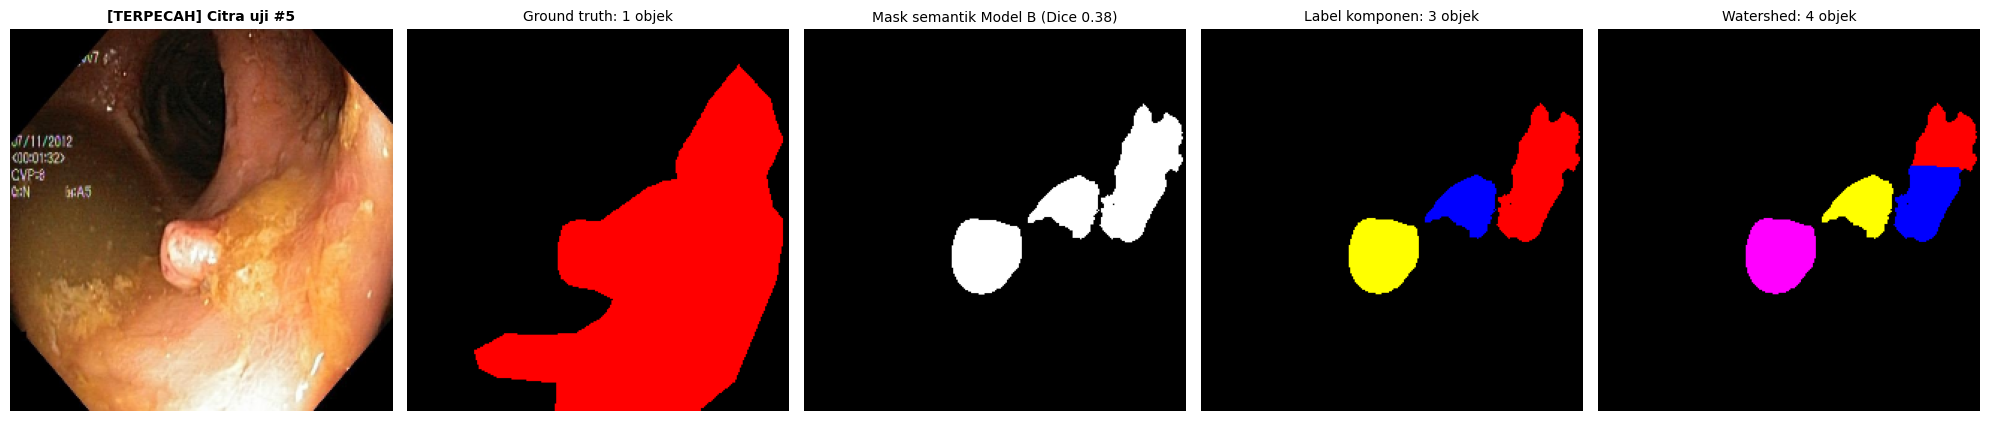


[Klasifikasi] Citra uji yang berisi polip (GT): 150 dari 150 -> label citra hampir selalu 'ada polip', tanpa informasi posisi, luas, atau bentuk.

[Deteksi] Citra pada Gambar 3 (citra uji #111) - prediksi Model B:
 Objek  Luas mask (px)  Luas kotak (px)  Kotak / mask (x)  Latar dalam kotak (%)  Kebulatan (solidity)
     1            4020             5418              1.35                   25.8                  0.94
     2            4142             5214              1.26                   20.6                  0.97

[Deteksi] Seluruh data uji, 156 objek ground truth:
  Rasio luas kotak / luas objek : median 1.42x | rata-rata 1.48x
  Bagian kotak yang sebenarnya latar: median 29.4% | rata-rata 30.9%
  Kebulatan (solidity) objek     : median 0.96 (1.0 = cembung sempurna)
  Kotak hanya memberi posisi dan ukuran kasar; luas sebenarnya dan kontur hanya ada pada mask.


In [ ]:
# ============ LANGKAH 6 (lanjutan): BUKTI INDIKATOR 1 & 2 ============
# ---------- (A) INDIKATOR 1: kapan mask semantik gagal memisahkan objek? ----------
def count_merges(gt, pred):
    """Jumlah komponen prediksi yang menutupi >= 2 objek ground truth (objek menyatu)."""
    gl, pl = label(gt), label(pred)
    merged = 0
    for p in range(1, pl.max() + 1):
        ids = np.unique(gl[(pl == p) & (gl > 0)])
        if len(ids) >= 2:
            merged += 1
    return merged

df_inst['n_merge'] = [count_merges(clean_mask(r['gt']), clean_mask(r['pred'])) for r in res_B]

def kategori(r):
    if r.n_gt == 0:                return 'GT kosong'
    if r.n_merge >= 1:             return 'Menyatu (>=2 objek GT jadi 1 komponen)'
    if r.n_pred > r.n_gt:          return 'Terpecah (komponen prediksi > objek GT)'
    if r.n_pred == r.n_gt:         return 'Jumlah objek sama'
    return 'Objek terlewat (komponen prediksi < objek GT)'
df_inst['kategori'] = df_inst.apply(kategori, axis=1)
print("Rekap kesesuaian jumlah objek pada data uji (Model B):")
print(df_inst['kategori'].value_counts().to_string())

cases = []   # (tag, baris df)
merge_rows = df_inst[df_inst.n_merge >= 1].sort_values(['n_merge', 'dice'], ascending=[False, False]).head(2)
cases += [('MENYATU', r) for _, r in merge_rows.iterrows()]
frag_rows = df_inst[df_inst.kategori.str.startswith('Terpecah')].assign(sel=lambda d: d.n_pred - d.n_gt) \
                .sort_values(['sel', 'dice'], ascending=[False, False]).head(1)
cases += [('TERPECAH', r) for _, r in frag_rows.iterrows()]

if len(merge_rows) == 0:
    print("\nTidak ada citra uji dengan objek menyatu pada prediksi Model B; laporkan ini apa adanya.")
if cases:
    fig, axes = plt.subplots(len(cases), 5, figsize=(20, 4.2 * len(cases)), squeeze=False)
    for row, (tag, r) in enumerate(cases):
        it = res_B[int(r.idx)]
        raw = get_raw_resized_img(it['idx'])
        gt_c, pr_c = clean_mask(it['gt']), clean_mask(it['pred'])
        ws = watershed_instances(pr_c)
        axes[row, 0].imshow(raw);                                   axes[row, 0].set_title(f"[{tag}] Citra uji #{it['idx']}", fontsize=10, fontweight='bold')
        axes[row, 1].imshow(label2rgb(label(gt_c), bg_label=0));    axes[row, 1].set_title(f"Ground truth: {label(gt_c).max()} objek", fontsize=10)
        axes[row, 2].imshow(pr_c, cmap='gray');                     axes[row, 2].set_title(f"Mask semantik Model B (Dice {it['dice']:.2f})", fontsize=10)
        axes[row, 3].imshow(label2rgb(label(pr_c), bg_label=0));    axes[row, 3].set_title(f"Label komponen: {label(pr_c).max()} objek", fontsize=10)
        axes[row, 4].imshow(label2rgb(ws, bg_label=0));             axes[row, 4].set_title(f"Watershed: {ws.max()} objek", fontsize=10)
        for ax in axes[row]:
            ax.axis('off')
    plt.tight_layout()
    plt.savefig('Gambar_4_Kegagalan_Semantik_vs_Instance.png', dpi=300)
    plt.show()

# ---------- (B) INDIKATOR 2: informasi yang hilang pada klasifikasi dan deteksi ----------
# (1) Klasifikasi: label citra hanya 1 bit
n_pos_gt = int((df_inst.n_gt > 0).sum())
print(f"\n[Klasifikasi] Citra uji yang berisi polip (GT): {n_pos_gt} dari {len(df_inst)} "
      f"-> label citra hampir selalu 'ada polip', tanpa informasi posisi, luas, atau bentuk.")

# (2) Deteksi: bounding box vs mask, citra pada Gambar 3
def comp_table(mask_lbl):
    rows = []
    for p in regionprops(mask_lbl):
        minr, minc, maxr, maxc = p.bbox
        box_area = (maxr - minr) * (maxc - minc)
        rows.append({'Objek': p.label, 'Luas mask (px)': int(p.area), 'Luas kotak (px)': int(box_area),
                     'Kotak / mask (x)': round(box_area / p.area, 2),
                     'Latar dalam kotak (%)': round(100 * (1 - p.area / box_area), 1),
                     'Kebulatan (solidity)': round(p.solidity, 2)})
    return pd.DataFrame(rows)

print(f"\n[Deteksi] Citra pada Gambar 3 (citra uji #{item['idx']}) - prediksi Model B:")
tbl_g3 = comp_table(instance_mask)
print(tbl_g3.to_string(index=False))

# (3) Seluruh data uji (komponen ground truth)
allc = pd.concat([comp_table(label(clean_mask(r['gt']))) for r in res_B], ignore_index=True)
print(f"\n[Deteksi] Seluruh data uji, {len(allc)} objek ground truth:")
print(f"  Rasio luas kotak / luas objek : median {allc['Kotak / mask (x)'].median():.2f}x | rata-rata {allc['Kotak / mask (x)'].mean():.2f}x")
print(f"  Bagian kotak yang sebenarnya latar: median {allc['Latar dalam kotak (%)'].median():.1f}% | rata-rata {allc['Latar dalam kotak (%)'].mean():.1f}%")
print(f"  Kebulatan (solidity) objek     : median {allc['Kebulatan (solidity)'].median():.2f} (1.0 = cembung sempurna)")
print("  Kotak hanya memberi posisi dan ukuran kasar; luas sebenarnya dan kontur hanya ada pada mask.")